# CO5085 E1 — Phân loại ảnh cho Colab

Notebook này được chạy trên Google Colab để thực hiện thí nghiệm phân loại ảnh cho bài tập E1. Hệ thống sẽ tự phát hiện đường dẫn repo, kiểm tra môi trường, đọc cấu hình, huấn luyện ba mô hình và lưu các chỉ số, biểu đồ cũng như so sánh kết quả.

## 1. Cài đặt thư viện và kiểm tra môi trường Colab

Quá trình bắt đầu bằng việc xác nhận GPU và trạng thái môi trường Colab trước khi chạy huấn luyện. Bước này giúp đảm bảo dự án chạy đúng với bộ dữ liệu và cấu hình tối ưu.

In [1]:
!nvidia-smi

import torch

print("PyTorch version:", torch.__version__)
print("GPU is available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Device Name:", torch.cuda.get_device_name(0))

Wed Oct 14 15:43:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os

if not os.path.exists("/content/deep-learning-computer-vision-co5085"):
    %cd /content
    !git clone https://github.com/hoctran19-cyber/deep-learning-computer-vision-co5085.git
    %cd /content/deep-learning-computer-vision-co5085/E1

!pwd
!ls -la

/content
Cloning into 'deep-learning-computer-vision-co5085'...
remote: Enumerating objects: 130, done.
remote: Counting objects: 100% (130/130), done.
remote: Compressing objects: 100% (88/88), done.
remote: Total 130 (delta 45), reused 109 (delta 24), pack-reused 0 (from 0)
Receiving objects: 100% (130/130), 1.13 MiB | 3.67 MiB/s, done.
Resolving deltas: 100% (45/45), done.
/content/deep-learning-computer-vision-co5085/E1
/content/deep-learning-computer-vision-co5085/E1
total 64
drwxr-xr-x  8 root root  4096 Oct 14 15:43 .
drwxr-xr-x 13 root root  4096 Oct 14 15:43 ..
drwxr-xr-x  2 root root  4096 Oct 14 15:43 configs
-rw-r--r--  1 root root   150 Oct 14 15:43 .gitignore
-rw-r--r--  1 root root 20415 Oct 14 15:43 index.html
drwxr-xr-x  2 root root  4096 Oct 14 15:43 models
drwxr-xr-x  2 root root  4096 Oct 14 15:43 notebooks
-rw-r--r--  1 root root  3402 Oct 14 15:43 README.md
-rw-r--r--  1 root root    70 Oct 14 15:43 requirements.txt
drwxr-xr-x  4 root root  4096 Oct 14 15:43 resul

In [3]:
!cat configs/config.yaml

!find . -maxdepth 3 -type f | sort

# E1 experiment configuration. Dataset files are downloaded only when code is run.
seed: 42

dataset:
  name: fashion_mnist  # FashionMNIST, MNIST, or CIFAR10
  data_dir: data
  num_workers: 2
  download: true

training:
  batch_size: 128
  epochs: 10
  learning_rate: 0.001

optimizer:
  name: Adam

experiment:
  validation_split: 0.1

model:
  name: cnn  # softmax, mlp, or cnn
  mlp_hidden_dims: [128, 64]
  cnn_channels: [32, 64]
  dropout: 0.0

output:
  figures_dir: results/figures
  metrics_dir: results/metrics
  checkpoints_dir: results/checkpoints
./configs/config.yaml
./.gitignore
./index.html
./models/cnn.pth
./models/mlp.pth
./models/softmax.pth
./notebooks/E1_experiment.ipynb
./README.md
./requirements.txt
./results/analysis.md
./results/figures/cnn_confusion_matrix.png
./results/figures/cnn_learning_curves.png
./results/figures/cnn_misclassified.png
./results/figures/.gitkeep
./results/figures/mlp_confusion_matrix.png
./results/figures/mlp_learning_curves.png
./results/figur

## 2. Cài đặt phụ thuộc và import module của dự án

Sau khi kiểm tra môi trường, các gói cần thiết sẽ được cài đặt và thực hiện import các module từ repo để đảm bảo mọi phần từ dữ liệu đến mô hình đều sẵn sàng.

In [ ]:
!pip install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 75.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.5/947.5 kB 61.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.2/60.2 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 95.2 MB/s eta 0:00:00:00:01


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cpu
CUDA available: False


In [7]:
import sys
import os

# Thêm đường dẫn E1 vào sys.path để đảm bảo import đúng
repo_path = "/content/deep-learning-computer-vision-co5085/E1"
if os.path.exists(repo_path) and repo_path not in sys.path:
    sys.path.append(repo_path)

from src.models import SoftmaxClassifier, MLPClassifier, CNNClassifier
from src.datasets import *
from src.train import *
from src.evaluate import *
from src.utils import *

print("Imports OK!")

Imports OK!


## 3. Smoke test mô hình

Trước khi huấn luyện thật, một kiểm tra nhanh được thực hiện để xác nhận các lớp mô hình hoạt động ổn định và đầu ra (output) có hình dạng chuẩn xác với dữ liệu đầu vào.

In [4]:
import torch

x = torch.randn(4, 1, 28, 28)

In [8]:
model = SoftmaxClassifier(
    input_shape=(1, 28, 28),
    num_classes=10
)
y = model(x)

print("Softmax:", y.shape)

Softmax: torch.Size([4, 10])


In [9]:
model = MLPClassifier(
    input_shape=(1, 28, 28),
    num_classes=10
)
y = model(x)

print("MLP:", y.shape)

MLP: torch.Size([4, 10])


In [ ]:
!cat configs/config.yaml

!find . -maxdepth 3 -type f | sort

CNN: torch.Size([4, 10])


In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


## 4. Kiểm tra CLI của training và chạy thử 1 epoch

Việc xác nhận script train chạy đúng cách qua CLI là rất cần thiết trước khi thực hiện huấn luyện toàn bộ mô hình, vì đây là phần quan trọng nhất của quy trình thực nghiệm.

In [12]:
!python -m src.train --help

usage: train.py [-h] --model {softmax,mlp,cnn} [--config CONFIG]
                [--epochs EPOCHS] [--batch-size BATCH_SIZE] [--lr LR]

Train one E1 classifier.

options:
  -h, --help            show this help message and exit
  --model {softmax,mlp,cnn}
  --config CONFIG
  --epochs EPOCHS
  --batch-size BATCH_SIZE
  --lr LR


In [13]:
!python -m src.train --model softmax --epochs 1

100% 26.4M/26.4M [00:01<00:00, 13.8MB/s]
100% 29.5k/29.5k [00:00<00:00, 205kB/s]
100% 4.42M/4.42M [00:01<00:00, 3.82MB/s]
100% 5.15k/5.15k [00:00<00:00, 42.3MB/s]
Completed softmax on cuda; test accuracy: 0.8207


## 5. Huấn luyện 3 mô hình

Sau khi đã xác nhận môi trường và CLI hoạt động ổn định, quá trình huấn luyện ba mô hình: Softmax, MLP và CNN sẽ được tiến hành. Mỗi mô hình sẽ tự động lưu lại các thông số đánh giá (metrics) và so sánh độ chính xác trên tập kiểm thử.

In [14]:
!python -m src.train --model softmax --epochs 10

Completed softmax on cuda; test accuracy: 0.8419


In [15]:
!python -m src.train --model mlp --epochs 10

Completed mlp on cuda; test accuracy: 0.8792


In [16]:
!python -m src.train --model cnn --epochs 10

Completed cnn on cuda; test accuracy: 0.9111


## 6. Kiểm tra kết quả đầu ra

Danh sách file sau khi huấn luyện được kiểm tra lại nhằm xác nhận hệ thống đã sinh ra đầy đủ các file metrics, CSV so sánh và biểu đồ ma trận nhầm lẫn (confusion matrix) cho mỗi mô hình.

In [17]:
!find results -maxdepth 3 -type f | sort

results/analysis.md
results/checkpoints/cnn.pt
results/checkpoints/mlp.pt
results/checkpoints/softmax.pt
results/figures/cnn_confusion_matrix.png
results/figures/cnn_learning_curves.png
results/figures/cnn_misclassified.png
results/figures/.gitkeep
results/figures/mlp_confusion_matrix.png
results/figures/mlp_learning_curves.png
results/figures/mlp_misclassified.png
results/figures/softmax_confusion_matrix.png
results/figures/softmax_learning_curves.png
results/figures/softmax_misclassified.png
results/metrics/cnn.json
results/metrics/.gitkeep
results/metrics.json
results/metrics/mlp.json
results/metrics/model_comparison.csv
results/metrics/softmax.json


In [18]:
import pandas as pd

df = pd.read_csv("results/metrics/model_comparison.csv")
df

,model,test_accuracy,num_parameters,best_val_accuracy,training_time
0,softmax,0.8419,7850,0.852500,104.962400
1,mlp,0.8792,109386,0.886667,106.991876
2,cnn,0.9111,50186,0.920333,112.993598


In [19]:
import json

for model_name in ["softmax", "mlp", "cnn"]:
    print(f"\n===== {model_name.upper()} =====")
    with open(f"results/metrics/{model_name}.json") as f:
        data = json.load(f)
    print("test_accuracy:", data.get("test_accuracy"))
    print("best_val_accuracy:", data.get("best_val_accuracy"))
    print("num_parameters:", data.get("num_parameters"))
    print("history keys:", list(data["history"].keys()))


===== SOFTMAX =====
test_accuracy: 0.8419
best_val_accuracy: 0.8525
num_parameters: 7850
history keys: ['train_loss', 'validation_loss', 'train_accuracy', 'validation_accuracy']

===== MLP =====
test_accuracy: 0.8792
best_val_accuracy: 0.8866666666666667
num_parameters: 109386
history keys: ['train_loss', 'validation_loss', 'train_accuracy', 'validation_accuracy']

===== CNN =====
test_accuracy: 0.9111
best_val_accuracy: 0.9203333333333333
num_parameters: 50186
history keys: ['train_loss', 'validation_loss', 'train_accuracy', 'validation_accuracy']


===== SOFTMAX =====


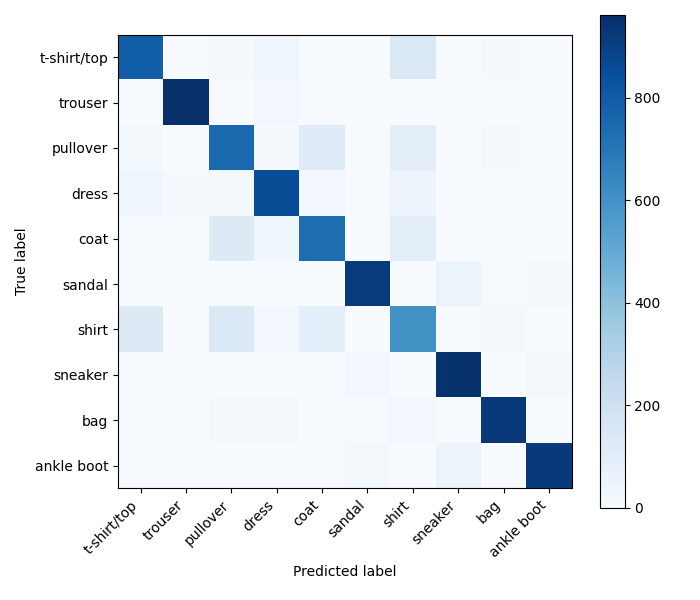

===== MLP =====


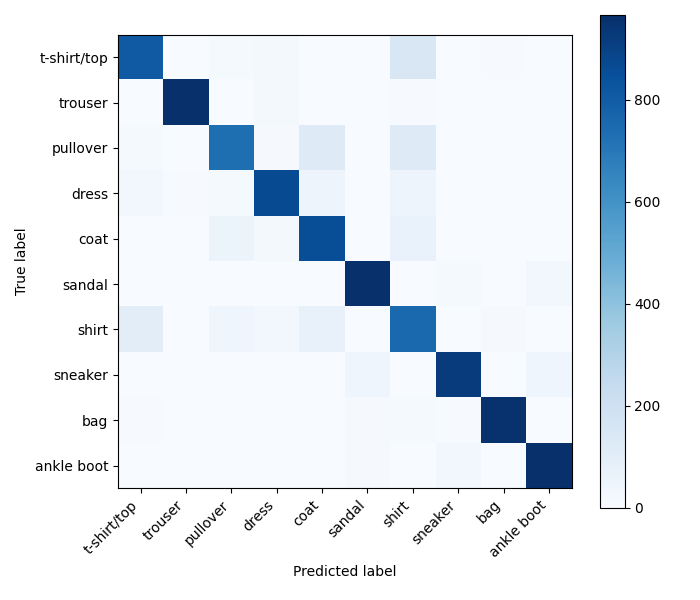

===== CNN =====


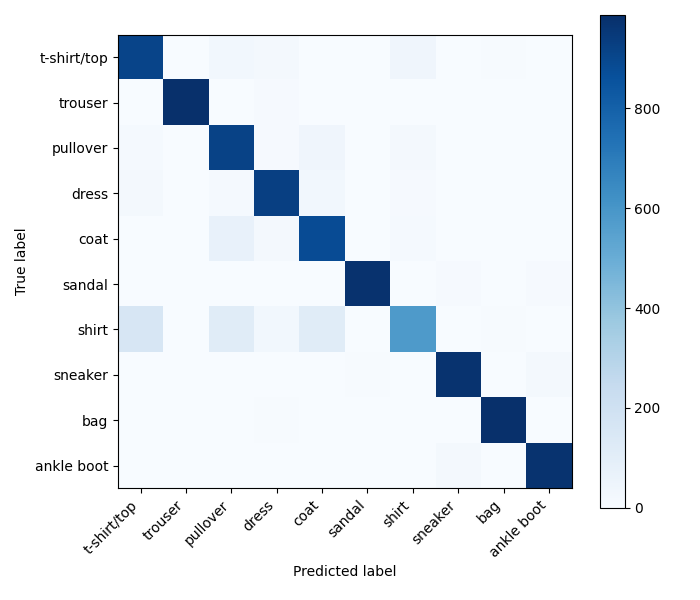

In [21]:
from IPython.display import Image, display

for model_name in ["softmax", "mlp", "cnn"]:
    print(f"===== {model_name.upper()} =====")
    display(Image(filename=f"results/figures/{model_name}_confusion_matrix.png"))

In [26]:
import os

# Tạo các thư mục đầu ra nếu chúng chưa tồn tại
# Thư mục 'results' chứa kết quả thử nghiệm (metrics, hình ảnh)
# Thư mục 'models' dùng để lưu trữ các trọng số mô hình đã huấn luyện hoàn chỉnh
os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)

In [27]:
# Liệt kê tất cả các tệp tin được tạo ra trong thư mục results
# Việc này giúp kiểm tra xem các hình ảnh, checkpoints và file metrics đã được lưu đúng vị trí hay chưa
!find /content/deep-learning-computer-vision-co5085/E1/results -type f

/content/deep-learning-computer-vision-co5085/E1/results/figures/softmax_misclassified.png
/content/deep-learning-computer-vision-co5085/E1/results/figures/softmax_learning_curves.png
/content/deep-learning-computer-vision-co5085/E1/results/figures/.gitkeep
/content/deep-learning-computer-vision-co5085/E1/results/figures/cnn_confusion_matrix.png
/content/deep-learning-computer-vision-co5085/E1/results/figures/cnn_misclassified.png
/content/deep-learning-computer-vision-co5085/E1/results/figures/mlp_misclassified.png
/content/deep-learning-computer-vision-co5085/E1/results/figures/mlp_learning_curves.png
/content/deep-learning-computer-vision-co5085/E1/results/figures/softmax_confusion_matrix.png
/content/deep-learning-computer-vision-co5085/E1/results/figures/mlp_confusion_matrix.png
/content/deep-learning-computer-vision-co5085/E1/results/figures/cnn_learning_curves.png
/content/deep-learning-computer-vision-co5085/E1/results/analysis.md
/content/deep-learning-computer-vision-co5085/E

In [28]:
import shutil
import os

# Xác định đường dẫn thư mục gốc và các thư mục liên quan
base_dir = "/content/deep-learning-computer-vision-co5085/E1"
checkpoint_dir = os.path.join(base_dir, "results/checkpoints")
models_dir = os.path.join(base_dir, "models")
os.makedirs(models_dir, exist_ok=True)

# Sao chép và đổi tên các file checkpoint từ định dạng .pt (trong results/checkpoints)
# sang định dạng .pth (trong thư mục models) cho cả 3 kiến trúc: softmax, mlp, cnn
for model_name in ["softmax", "mlp", "cnn"]:
    src_path = os.path.join(checkpoint_dir, f"{model_name}.pt")
    dst_path = os.path.join(models_dir, f"{model_name}.pth")
    if os.path.exists(src_path):
        shutil.copy(src_path, dst_path)
        print(f"Đã lưu model thành công: {dst_path}")
    else:
        print(f"Không tìm thấy checkpoint tại: {src_path}")

Đã lưu model thành công: /content/deep-learning-computer-vision-co5085/E1/models/softmax.pth
Đã lưu model thành công: /content/deep-learning-computer-vision-co5085/E1/models/mlp.pth
Đã lưu model thành công: /content/deep-learning-computer-vision-co5085/E1/models/cnn.pth


In [29]:
import json
import os

# Định nghĩa đường dẫn tuyệt đối cho các thư mục metrics đầu vào và tệp JSON tổng hợp đầu ra
base_dir = "/content/deep-learning-computer-vision-co5085/E1"
metrics_dir = os.path.join(base_dir, "results/metrics")
output_file = os.path.join(base_dir, "results/metrics.json")

metrics = {}

# Đọc dữ liệu đánh giá riêng lẻ của từng mô hình (softmax, mlp, cnn)
# và trích xuất các thông số quan trọng: test_accuracy, num_parameters, best_val_accuracy, training_time
for name in ["softmax", "mlp", "cnn"]:
    path = os.path.join(metrics_dir, f"{name}.json")
    if os.path.exists(path):
        with open(path, "r") as f:
            data = json.load(f)
        metrics[name] = {
            "test_accuracy": data.get("test_accuracy"),
            "num_parameters": data.get("num_parameters"),
            "best_val_accuracy": data.get("best_val_accuracy"),
            "training_time": data.get("training_time")
        }
    else:
        print(f"Không tìm thấy tệp metrics tại: {path}")

# Ghi tệp JSON tổng hợp kết quả của cả 3 mô hình để tiện cho việc so sánh và đánh giá chung
with open(output_file, "w") as f:
    json.dump(metrics, f, indent=4)

print(f"Đã tổng hợp xong kết quả lưu vào {output_file}:")
print(json.dumps(metrics, indent=2))

Đã tổng hợp xong kết quả lưu vào /content/deep-learning-computer-vision-co5085/E1/results/metrics.json:
{
  "softmax": {
    "test_accuracy": 0.8419,
    "num_parameters": 7850,
    "best_val_accuracy": 0.8525,
    "training_time": 104.96239994400003
  },
  "mlp": {
    "test_accuracy": 0.8792,
    "num_parameters": 109386,
    "best_val_accuracy": 0.8866666666666667,
    "training_time": 106.99187630000006
  },
  "cnn": {
    "test_accuracy": 0.9111,
    "num_parameters": 50186,
    "best_val_accuracy": 0.9203333333333333,
    "training_time": 112.99359806999996
  }
}


### 8. Thực hiện Commit và Push kết quả lên Git

In [51]:
# Cấu hình thông tin cá nhân Git của bạn
# Thay đổi thông tin 'Your Name' và 'your.email@example.com' bên dưới cho đúng tài khoản của bạn
!git config --global user.name "Tran Thai Hoc"
!git config --global user.email "hoc.tran19@hcmut.edu.vn"
print("Cấu hình Git thành công!")

Cấu hình Git thành công!


In [52]:
# Xem trạng thái các tệp tin đã thay đổi hoặc mới được tạo ra
!git status

On branch main
Your branch is ahead of 'origin/main' by 1 commit.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean


In [46]:
# Thêm các tệp tin kết quả thí nghiệm mới tạo ra vào vùng lưu tạm (Staging Area)
!git add results/metrics.json models/*.pth

# Nếu muốn thêm tất cả các file ảnh/metrics mới
!git add results/

# Xác nhận lại các file đã được add thành công
!git status

On branch main
Your branch is ahead of 'origin/main' by 1 commit.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean


In [47]:
# Thực hiện commit các thay đổi kèm thông điệp
!git commit -m "Feat: Hoàn thành huấn luyện 3 mô hình và xuất báo cáo metrics E1"

On branch main
Your branch is ahead of 'origin/main' by 1 commit.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean


Để đẩy mã nguồn lên GitHub an toàn, hãy lưu PAT trong biến môi trường `GITHUB_TOKEN` và không hard-code token trực tiếp trong notebook.

```python
# Ví dụ: export GITHUB_TOKEN=your_personal_access_token
```

In [ ]:
import os

GITHUB_TOKEN = os.environ.get("GITHUB_TOKEN")
REPO_OWNER = "hoctran19-cyber"
REPO_NAME = "deep-learning-computer-vision-co5085"

if not GITHUB_TOKEN:
    raise ValueError("Set the GITHUB_TOKEN environment variable before pushing.")

!git push https://{GITHUB_TOKEN}@github.com/{REPO_OWNER}/{REPO_NAME}.git

Everything up-to-date


### 9. Sao lưu và Commit chính tệp Notebook này lên GitHub
*Chú ý: Đảm bảo bạn đã nhấn nút Save (Ctrl + S) cho Notebook này trước khi chạy các lệnh dưới đây.*

In [60]:
import os
import glob
import shutil

# Tìm kiếm tất cả các tệp .ipynb trong thư mục /content và các thư mục con (tránh checkpoint)
ipynb_files = []
for path in ["/content/*.ipynb", "/content/gdrive/MyDrive/*.ipynb"]:
    try:
        ipynb_files.extend(glob.glob(path))
    except Exception:
        pass

print("Các file notebook tìm thấy trong môi trường:", ipynb_files)

# Xác định đường dẫn đích trong repo
repo_notebook = "/content/deep-learning-computer-vision-co5085/E1/notebooks/E1_experiment.ipynb"

# Tìm file có tên tương tự để làm nguồn đồng bộ
found_source = None
for f in ipynb_files:
    if "E1_experiment" in f and repo_notebook not in f:
        found_source = f
        break

if found_source:
    shutil.copy(found_source, repo_notebook)
    print(f"Đã đồng bộ thành công bản lưu từ {found_source} vào repo {repo_notebook}!")
else:
    # Nếu không tìm thấy file ngoài repo, tự copy từ file lưu trữ hiện tại của phiên làm việc
    colab_env_notebooks = [f for f in glob.glob("/content/**/*.ipynb", recursive=True) if "checkpoint" not in f]
    print("Tất cả tệp .ipynb khả dụng:", colab_env_notebooks)

!git status

Các file notebook tìm thấy trong môi trường: []
Tất cả tệp .ipynb khả dụng: ['/content/deep-learning-computer-vision-co5085/E1/notebooks/E1_experiment.ipynb']
On branch main
Your branch is ahead of 'origin/main' by 1 commit.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean


In [57]:
# Thêm tệp notebook vào Git staging và ép buộc cập nhật
!git add -u
!git add /content/deep-learning-computer-vision-co5085/E1/notebooks/E1_experiment.ipynb 2>/dev/null || true

# Thực hiện commit các thay đổi của notebook
!git commit -m "Chore: Cập nhật tệp notebook thí nghiệm E1 mới nhất" || echo "Không có thay đổi nào để commit."

On branch main
Your branch is ahead of 'origin/main' by 1 commit.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean
Không có thay đổi nào để commit.


In [ ]:
import os

GITHUB_TOKEN = os.environ.get("GITHUB_TOKEN")
REPO_OWNER = "hoctran19-cyber"
REPO_NAME = "deep-learning-computer-vision-co5085"

if not GITHUB_TOKEN:
    raise ValueError("Set the GITHUB_TOKEN environment variable before pushing.")

!git push https://{GITHUB_TOKEN}@github.com/{REPO_OWNER}/{REPO_NAME}.git

Everything up-to-date


## 7. Kết luận và nhận xét

Dựa trên các thông số thu được, hiệu suất của ba mô hình sẽ được so sánh trực quan, đồng thời đánh giá mức độ ổn định của quá trình huấn luyện để rút ra nhận xét về mô hình tối ưu nhất cho bài toán phân loại ảnh Fashion-MNIST.